# LLM judge로 궤적 평가

**이 노트북에서 할 일**

1. 01절의 답만 틀린 궤적으로, 모드와 평가 모델이 궤적에서 무엇을 보는지 견줍니다.
2. 도구 둘을 붙인 에이전트를 실제 모델로 한 번 실행해 궤적을 만듭니다.
3. 그 궤적을 02절의 모드와 평가 모델로 함께 판정하고, 답 글 하나만 바꿔 다시 판정합니다.

**준비물** — 프로젝트 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
모델 요청은 4~6절에서만 나갑니다.
교재 출력에서는 에이전트 요청 3번과 평가 모델 요청 2번, 모두 5번이었습니다.
예상 비용은 요금표로 어림해 약 0.003달러이고, 청구 금액과는 다를 수 있습니다.
2~3절은 모델 요청 없이, 코드로 적은 궤적과 라이브러리 함수만 씁니다.

읽는 파일은 `.env`와 같은 폴더의 도구 파일 `eval_tools.py`이고, 쓰는 파일은 없습니다.
걸린 시간은 재지 않았습니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 agentevals 0.0.9와 langchain 1.4.0입니다.
모델을 부르는 langchain-openai는 1.6.0, 키를 읽는 python-dotenv는 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
평가 모델이 받는 글을 보고, 실제 에이전트 궤적을 두 방법으로 판정하는 자리입니다.
6~7절은 답 글 하나만 바꿔 다시 판정하고 요청 수를 세는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch29-agent-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 초록 상자 둘은 답만 틀린 궤적과 기준 궤적입니다. 답만 틀린 궤적은 도구 요청 둘이 기준과 같고 답 글이 7일, 기준 궤적은 답 글이 14일입니다. 두 상자에서 아래 칸 둘로 화살표가 갑니다. 왼쪽 칸 평가 모델에는 회색 상자 _format_inputs, 메시지마다 태그로 감싼 궤적 글에서 노란 상자 답 글·검색 결과 글·호출 ID 모두 들어 있음 True로 화살표가 갑니다. 그 아래 점선 테두리의 회색 상자 평가 모델, 3절에서 만들기만 함으로 점선 화살표가 이어집니다. 오른쪽 칸 궤적 맞춰 보기에는 파란 상자 모드 넷, 도구 요청의 이름과 인자만 짝지음에서 노란 상자 네 모드 모두 True로 화살표가 가는 그림](attachment:03-1-모드와-평가-모델이-보는-것.png)

위에서 아래로 읽습니다.
맨 위 초록 상자 둘은 노트북 2절에서 코드로 적은 두 궤적입니다.
오른쪽 칸은 2절에서 네 모드로 견준 결과이고, 왼쪽 칸은 같은 궤적을 평가 모델이 받는 글로 바꾼 결과입니다.
노란 상자 둘은 2절 셀 출력입니다.
앞 절반에서는 평가 모델을 부르지 않아, 점선 테두리의 회색 상자로 두었습니다.
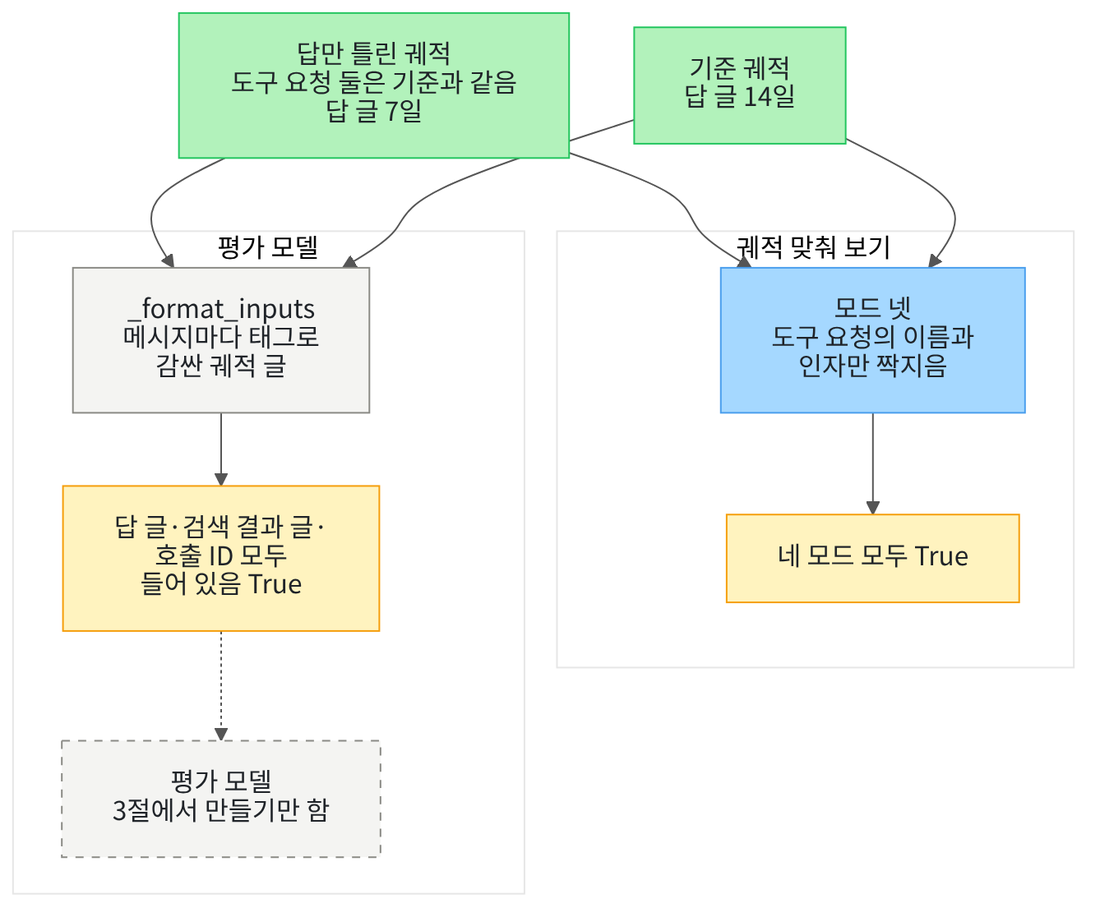

## 1. 준비

01·02절은 궤적을 코드 규칙으로 맞춰 봤습니다.
이 절은 모델이 궤적을 읽고 판정하는 평가 모델(judge)을 쓰고, 이 챕터에서 처음으로 에이전트를 실제로 실행합니다.
뜻과 구성은 본문 「핵심 개념」에서 풉니다.

첫 셀은 패키지 넷을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "agentevals==0.0.9" "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("agentevals:", version("agentevals"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
agentevals: 0.0.9
langchain: 1.4.0
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `agentevals: 0.0.9`, `langchain: 1.4.0`, `langchain-openai: 1.6.0`, `python-dotenv: 1.2.3`이 보입니다.
넷 모두 실습 폴더 잠금과 같은 판입니다.
패키지 langchain-openai는 모델을 부를 때, python-dotenv는 키를 읽을 때 씁니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
함수 `create_trajectory_llm_as_judge`는 평가 모델로 궤적을 판정하는 평가 함수를 만듭니다.
이름 `TRAJECTORY_ACCURACY_PROMPT_WITH_REFERENCE`는 라이브러리가 적어 둔 판정 머리글입니다.
함수 `_format_inputs`처럼 밑줄로 시작하는 이름은 라이브러리가 안에서 쓰는 함수입니다.
판이 바뀌면 달라질 수 있어, 이 절은 평가 모델이 받는 글을 볼 때만 씁니다.

In [2]:
# 궤적을 맞춰 보는 평가 함수·평가 모델로 판정하는 평가 함수를 만드는 함수와 판정 머리글을 가져옵니다
from agentevals.trajectory.llm import TRAJECTORY_ACCURACY_PROMPT_WITH_REFERENCE, _format_inputs, create_trajectory_llm_as_judge
from agentevals.trajectory.match import create_trajectory_match_evaluator
# 에이전트·호출 한도·모델·메시지 클래스·도구를 등록하는 줄을 가져옵니다(Ch 6·13·19·21·22)
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, HumanMessage
from langchain.tools import tool
# 앞에서 배운 함수는 도구 파일에서 가져옵니다
from eval_tools import called_tool_names, estimate_cost, four_modes, make_trajectory, show_messages, sum_usage, tool_call_names, trajectory_pass

print("도구 파일에서 가져온 함수:", "called_tool_names, estimate_cost, four_modes, make_trajectory, show_messages, sum_usage, tool_call_names, trajectory_pass")

도구 파일에서 가져온 함수: called_tool_names, estimate_cost, four_modes, make_trajectory, show_messages, sum_usage, tool_call_names, trajectory_pass


**결과 읽기** — 라벨 `도구 파일에서 가져온 함수:` 뒤에 `four_modes`·`sum_usage`·`estimate_cost` 등 함수 여덟의 이름이 보입니다.
앞에서 배운 함수는 `eval_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.

노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

함수 `four_modes(messages, reference, evaluators)`는 02절 노트북에서 처음 적은 함수이고, 이 절부터 도구 파일에서 가져옵니다.
도구 파일에는 02절 셀의 주석과 본문을 글자 그대로 옮겼고, 인자도 02절과 같습니다.
함수 `sum_usage(messages)`와 `estimate_cost(usage, input_rate, cached_input_rate, output_rate)`는 Ch 19 05절과 Ch 6 06절에서 배웠습니다.
두 함수는 Ch 21 도구 파일 `runner_tools.py`의 함수와 설명 주석·본문이 같습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-29에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장과 판정이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
이 모델 객체 하나를 3절의 평가 모델과 4절의 에이전트에 함께 넘깁니다.

## 2. 모드와 평가 모델이 보는 것

01절에서 본 것처럼, 모드 `strict`는 도구 차례가 같고 답 글만 틀린 궤적을 참으로 봤습니다.
이 절의 앞 절반은 모델을 부르지 않고, 같은 궤적을 평가 모델이 어떤 글로 받는지 봅니다.
다음 셀은 01절과 같은 질문·기준 답·결과 글을 정합니다.
4절에서 만들 도구 함수도 이 결과 글을 내놓습니다.

In [5]:
# 질문과 기준 답, 도구마다 돌아올 결과 글을 정합니다(01절과 같은 글 — 4절의 도구 함수도 이 글을 내놓음)
question = "일반 도서는 며칠 동안 빌릴 수 있나요?"
reference_answer = "일반 도서는 14일 동안 빌릴 수 있습니다."
tool_results = {
    "search_documents": "[LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.",
    "check_source": "LIB-001 문서가 있습니다. 제목: 도서 대출 기간",
}
print("질문:", question)
print("기준 답:", reference_answer)
print("결과 글을 정한 도구:", list(tool_results))

질문: 일반 도서는 며칠 동안 빌릴 수 있나요?
기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.
결과 글을 정한 도구: ['search_documents', 'check_source']


**결과 읽기** — 출력 줄 `기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.`가 보입니다.
라벨 `결과 글을 정한 도구:` 뒤에는 `'search_documents'`와 `'check_source'`가 있습니다.

다음 셀은 01절과 같은 도구 요청 둘로 기준 궤적을 만듭니다.
함수 `make_trajectory`와 `called_tool_names`는 01절에서 처음 적은 함수입니다.

In [6]:
# 01절과 같은 도구 요청 둘로 기준 궤적을 만들고, 도구 차례와 메시지 수를 봅니다
search_args = {"query": "도서 대출 기간"}
source_args = {"doc_id": "LIB-001"}
reference_calls = [
    {"name": "search_documents", "args": search_args, "id": "call_1", "type": "tool_call"},
    {"name": "check_source", "args": source_args, "id": "call_2", "type": "tool_call"},
]
reference = make_trajectory(question, reference_calls, tool_results, reference_answer)
print("기준 궤적의 도구 차례:", called_tool_names(reference))
print("메시지 수:", len(reference))

기준 궤적의 도구 차례: ['search_documents', 'check_source']
메시지 수: 6


**결과 읽기** — 출력 줄 `기준 궤적의 도구 차례: ['search_documents', 'check_source']`와 `메시지 수: 6`이 보입니다.
01·02절의 기준 궤적과 같은 요청이고, 메시지 수도 같습니다.

다음 셀은 01절처럼 도구 요청은 기준과 같고, 답 글만 「7일」로 틀린 궤적을 만듭니다.

In [7]:
# 01절처럼 도구 요청은 기준과 같고 답 글만 틀린 궤적을 만듭니다
wrong_text = "일반 도서는 7일 동안 빌릴 수 있습니다."
wrong_answer = make_trajectory(question, reference_calls, tool_results, wrong_text)
print("도구 차례:", called_tool_names(wrong_answer))
print("최종 답:", wrong_answer[-1].content)

도구 차례: ['search_documents', 'check_source']
최종 답: 일반 도서는 7일 동안 빌릴 수 있습니다.


**결과 읽기** — 출력 줄 `최종 답: 일반 도서는 7일 동안 빌릴 수 있습니다.`가 보입니다.
라벨 `도구 차례:` 뒤의 목록은 기준 궤적과 같습니다.

다음 셀은 02절처럼 모드 넷마다 평가 함수를 하나씩 만들어, 딕셔너리 `evaluators`에 모읍니다.
02절에서는 답만 틀린 궤적을 네 모드로 견주지 않았습니다.

In [8]:
# 02절처럼 모드 넷마다 궤적을 맞춰 보는 평가 함수를 하나씩 만들어, 모드 이름을 키로 모읍니다
modes = ["strict", "unordered", "subset", "superset"]
evaluators = {}
for mode in modes:
    evaluators[mode] = create_trajectory_match_evaluator(trajectory_match_mode=mode)
print("평가 함수를 만든 모드:", list(evaluators))

평가 함수를 만든 모드: ['strict', 'unordered', 'subset', 'superset']


**결과 읽기** — 출력 줄 `평가 함수를 만든 모드: ['strict', 'unordered', 'subset', 'superset']`이 보입니다.

다음 셀은 답만 틀린 궤적을 네 모드로 견줍니다.
함수 `four_modes`는 모드 이름을 키로 한 점수 딕셔너리를 내놓습니다.
실행 전에 예상해 봅니다.
답 글이 틀렸다는 것을 잡는 모드가 있을까요?

In [9]:
# 답만 틀린 궤적을 02절 함수 four_modes로 네 모드 모두에 견줍니다
wrong_row = four_modes(wrong_answer, reference, evaluators)
print("답만 틀림:", wrong_row)

답만 틀림: {'strict': True, 'unordered': True, 'subset': True, 'superset': True}


**결과 읽기** — 출력 줄 `답만 틀림: {'strict': True, 'unordered': True, 'subset': True, 'superset': True}`가 보입니다.
네 모드 모두 참이었습니다.

네 모드는 도구 요청의 이름과 인자를 짝지을 뿐, 메시지 글은 견주지 않습니다.
그래서 답이 틀린 궤적도 도구를 기준대로 불렀다면 참입니다.
답 글까지 보려면, 궤적을 글로 읽는 쪽이 있어야 합니다.

다음 셀은 평가 모델이 받을 궤적 글을 만듭니다.
함수 `_format_inputs`에 실제 궤적과 기준 궤적을 넣으면, 두 궤적을 글로 바꾼 값 둘을 튜플로 내놓습니다.
번호 `[0]`이 실제 궤적 글이고, 번호 `[1]`이 기준 궤적 글입니다.

In [10]:
# 평가 모델이 받을 궤적 글을 만듭니다(설치판 함수 _format_inputs — 실제 궤적 글과 기준 궤적 글을 튜플로 내놓음)
formatted = _format_inputs(wrong_answer, reference)
judge_text = formatted[0]
print("실제 궤적 글:")
print(judge_text)

실제 궤적 글:
<user>
일반 도서는 며칠 동안 빌릴 수 있나요?
</user>

<assistant>
<tool_call>
<name>search_documents</name>
<arguments>{"query": "도서 대출 기간"}</arguments>
</tool_call>
</assistant>

<tool>
<tool_result>
<id>call_1</id>
<content>[LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.</content>
</tool_result>
</tool>

<assistant>
<tool_call>
<name>check_source</name>
<arguments>{"doc_id": "LIB-001"}</arguments>
</tool_call>
</assistant>

<tool>
<tool_result>
<id>call_2</id>
<content>LIB-001 문서가 있습니다. 제목: 도서 대출 기간</content>
</tool_result>
</tool>

<assistant>
일반 도서는 7일 동안 빌릴 수 있습니다.
</assistant>


**결과 읽기** — 라벨 줄 `실제 궤적 글:` 아래가 평가 모델이 받는 궤적 글입니다.
메시지마다 `<user>`·`<assistant>`·`<tool>` 같은 태그로 감쌌습니다.
도구 요청은 `<tool_call>` 안에 이름과 인자를, 도구 메시지는 `<tool_result>` 안에 호출 ID와 글을 담았습니다.
마지막 `<assistant>` 태그 안에는 답 글 `일반 도서는 7일 동안 빌릴 수 있습니다.`가 그대로 있습니다.

이처럼 궤적의 메시지를 태그로 감싸 한 덩어리로 이은 글을, 이 절에서는 궤적 글이라고 부릅니다.
설치판 agentevals 0.0.9 `trajectory/llm.py` 77~95행이 이 함수입니다.
메시지를 태그로 감싸는 줄은 설치판 openevals 0.2.0 `utils.py` 427~454행에 있습니다.

다음 셀은 이 궤적 글에 답 글·검색 결과 글·호출 ID가 들어 있는지 봅니다.
셋 모두 모드 `strict`가 견주지 않는 것입니다.

In [11]:
# 궤적 글에 답 글·검색 결과 글·호출 ID가 들어 있는지 봅니다(모드는 셋 다 견주지 않음)
print("답 글이 들어 있는가:", wrong_text in judge_text)
print("검색 결과 글이 들어 있는가:", tool_results["search_documents"] in judge_text)
print("호출 ID가 들어 있는가:", "call_1" in judge_text)
print("기준 궤적 글에 기준 답이 들어 있는가:", reference_answer in formatted[1])

답 글이 들어 있는가: True
검색 결과 글이 들어 있는가: True
호출 ID가 들어 있는가: True
기준 궤적 글에 기준 답이 들어 있는가: True


**결과 읽기** — 네 줄 모두 `True`입니다.
출력 줄 `답 글이 들어 있는가: True`와 `검색 결과 글이 들어 있는가: True`가 보입니다.

평가 모델은 도구 요청뿐 아니라 답 글과 도구 결과 글까지 한 글로 받습니다.
그래서 답 글의 「7일」이 검색 결과 글의 「14일」과 맞지 않는다는 것도 글에 드러납니다.
호출 ID도 글에 들어갑니다.
4절 에이전트의 호출 ID는 모델 서비스가 정한 값이라, 실행마다 궤적 글이 조금씩 달라집니다.

## 3. 판정 기준과 평가 모델

Ch 15 02절에서는 판정할 기준을 적은 글을 판정 머리글이라고 불렀습니다.
이름 `TRAJECTORY_ACCURACY_PROMPT_WITH_REFERENCE`는 라이브러리가 적어 둔 영어 판정 머리글입니다.
머리글 안에는 판정 기준과, 두 궤적 글을 끼울 자리 둘이 있습니다.
다음 셀은 판정 기준 줄을 출력하고, 2절의 두 궤적 글을 끼운 요청 글의 글자 수를 셉니다.
글 메서드 `startswith`와 `format`은 처음 쓰는 이름이라, 셀 주석에 한 줄씩 풀었습니다.

In [12]:
# 판정 머리글에서 판정 기준 네 줄을 보고, 두 궤적 글을 끼운 요청 글의 글자 수를 셉니다
print("판정 기준:")
for line in TRAJECTORY_ACCURACY_PROMPT_WITH_REFERENCE.splitlines():
    # 글의 메서드 startswith는 글이 괄호 안의 글로 시작하면 참을 냅니다
    if line.startswith("  - "):
        print(line)
# 글의 메서드 format은 머리글 속 {outputs}·{reference_outputs} 자리에 같은 이름의 인자 값을 채웁니다
request_text = TRAJECTORY_ACCURACY_PROMPT_WITH_REFERENCE.format(outputs=judge_text, reference_outputs=formatted[1])
print("요청 글의 글자 수:", len(request_text))

판정 기준:
  - Makes logical sense between steps
  - Shows clear progression
  - Is relatively efficient, though it does not need to be perfectly efficient
  - Is semantically equivalent to the provided reference trajectory
요청 글의 글자 수: 1694


**결과 읽기** — 라벨 줄 `판정 기준:` 아래 네 줄이 판정 기준입니다.
출력 줄 `요청 글의 글자 수: 1694`가 보입니다.

네 줄은 차례대로 이렇게 풉니다.
단계와 단계가 논리적으로 이어지는가, 한 단계씩 나아가는가를 봅니다.
완벽하지 않아도 되지만 필요 없는 단계가 적은가, 기준 궤적과 뜻이 같은가도 봅니다.
평가 모델은 이 요청 글을 받아, 네 기준에 맞는지 참·거짓 하나로 판정합니다.

다음 셀은 평가 모델로 궤적을 판정하는 평가 함수를 만듭니다.
인자 `judge=`에는 1절에서 만든 모델 객체를, 인자 `prompt=`에는 판정 머리글을 넣습니다.
이 셀도 평가 함수를 만들기만 하고, 모델 요청은 보내지 않습니다.

In [13]:
# 모델 객체와 판정 머리글로, 평가 모델이 궤적을 판정하는 평가 함수를 만듭니다(아직 요청은 보내지 않음)
accuracy_judge = create_trajectory_llm_as_judge(judge=model, prompt=TRAJECTORY_ACCURACY_PROMPT_WITH_REFERENCE)
print("평가 함수의 종류:", type(accuracy_judge).__name__)

평가 함수의 종류: function


**결과 읽기** — 출력 줄 `평가 함수의 종류: function`이 보입니다.
01절의 궤적 맞춰 보기처럼, 만든 것은 부를 수 있는 함수입니다.

설치판 openevals 0.2.0 `llm.py`를 보면, 이 함수를 부를 때마다 모델에 요청을 1번 보냅니다.
모델은 칸 `reasoning`(글)과 칸 `score`(참·거짓)를 담은 JSON 형식으로 답합니다.
이 답할 모양도 요청 글과 함께 모델에 넘어갑니다.
모양의 설명 글에는 칸 `reasoning`을 「Thus, the score should be」로 끝내라는 말이 적혀 있습니다.
그래서 5절 판정 출력의 끝에 그 문장이 보입니다.

평가 함수는 이를 칸 `key`·`score`·`comment`·`metadata`의 딕셔너리로 내놓습니다.
칸 `comment`에 든 글, 곧 평가 모델이 그렇게 판정한 까닭을 판정 까닭이라고 부르겠습니다.
이 모양은 설치판 소스로 본 것이고, 노트북에서는 5절에서 처음 부릅니다.

## 4. 실제 에이전트로 궤적 만들기

지금까지의 궤적은 모두 코드로 적은 메시지 목록이었습니다.
이 절의 뒤 절반은 도구 둘을 붙인 에이전트를 실제 모델로 한 번 실행해, 그 결과를 궤적으로 씁니다.
이처럼 평가할 궤적을 만드는 에이전트를 평가받는 에이전트라고 부르겠습니다.

다음 셀은 검색 도구를 만듭니다.
Ch 19 01절처럼 `@tool` 줄은 아래 함수를 도구로 등록하고, 독스트링은 모델이 읽는 도구 설명이 됩니다.
이 검색 도구는 교재용이라, 어떤 검색어에도 2절 결과 글 딕셔너리의 검색 결과 글을 내놓습니다.

In [14]:
# 검색 도구를 만듭니다(교재용 — 어떤 검색어에도 2절 결과 글 딕셔너리의 검색 결과 글을 내놓음)
@tool
def search_documents(query: str):
    """도서관 규정 문서를 검색어로 찾아, 문서 ID를 붙인 글로 내놓습니다."""
    return tool_results["search_documents"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
매개변수 뒤의 `: str`은 Ch 19 01절에서 본 힌트로, 도구의 입력이 글이라고 알립니다.

다음 셀은 출처 확인 도구를 만듭니다.
문서 ID가 `LIB-001`이면 2절의 출처 확인 결과 글을, 아니면 그 문서가 없다는 글을 내놓습니다.

In [15]:
# 출처 확인 도구를 만듭니다(문서 ID가 LIB-001일 때만 문서가 있다고 내놓음)
@tool
def check_source(doc_id: str):
    """문서 ID로 그 문서가 있는지 확인하고, 있으면 제목을 내놓습니다."""
    if doc_id == "LIB-001":
        return tool_results["check_source"]
    return doc_id + " 문서가 없습니다."

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 두 도구를 모델 없이 직접 불러 봅니다.
Ch 19 01절처럼 메서드 `invoke`에 인자 딕셔너리를 넣습니다.

In [16]:
# 두 도구를 인자 딕셔너리로 직접 불러 봅니다(모델 요청 없음)
print("검색:", search_documents.invoke({"query": "책 대출 기간"}))
print("출처 확인:", check_source.invoke({"doc_id": "LIB-001"}))
print("없는 문서:", check_source.invoke({"doc_id": "LIB-002"}))

검색: [LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
출처 확인: LIB-001 문서가 있습니다. 제목: 도서 대출 기간
없는 문서: LIB-002 문서가 없습니다.


**결과 읽기** — 라벨 `검색:` 뒤에는 검색어 「책 대출 기간」과 상관없이 `[LIB-001]`로 시작하는 검색 결과 글이 있습니다.
출력 줄 `없는 문서: LIB-002 문서가 없습니다.`가 보입니다.
두 도구 모두 정해진 글을 내놓는 평범한 Python 함수라, 다시 실행해도 같은 글이 나옵니다.

다음 셀은 평가받는 에이전트를 만듭니다.
Ch 21 01절처럼 함수 `create_agent`에 모델 객체와 도구 목록, 시스템 메시지 글을 넘깁니다.
Ch 22 04절의 호출 한도 4를 붙여, invoke 한 번에 모델 요청이 4번을 넘지 않게 합니다.
Ch 20 03절의 설정 딕셔너리로 실행 한도 20도 줍니다.
시스템 메시지 글에는 검색한 뒤 출처를 확인하고 답하라는 차례를 적었습니다.

In [17]:
# 도구 둘·시스템 메시지 글·호출 한도 4로 평가받는 에이전트를 만듭니다(Ch 21 01절·Ch 22 04절 모양)
call_limit = ModelCallLimitMiddleware(run_limit=4, exit_behavior="end")
agent_rule = "도서관 규정 질문에는 먼저 search_documents로 문서를 찾고, 찾은 문서 ID로 check_source를 불러 문서가 있는지 확인한 뒤, 확인한 문서의 글만 근거로 한국어 한 문장으로 답하세요."
library_agent = create_agent(model, tools=[search_documents, check_source], system_prompt=agent_rule, middleware=[call_limit])
# 실행 한도는 Ch 20 03절의 설정 딕셔너리로 줍니다(그래프 단계 수 상한)
run_config = {"recursion_limit": 20}
print("에이전트의 종류:", type(library_agent).__name__)
print("실행 한도:", run_config["recursion_limit"])

에이전트의 종류: CompiledStateGraph
실행 한도: 20


**결과 읽기** — 출력 줄 `에이전트의 종류: CompiledStateGraph`와 `실행 한도: 20`이 보입니다.
Ch 21 01절에서 본 것처럼, 에이전트는 컴파일된 그래프입니다.

호출 한도는 모델 요청 수의 상한이고, 실행 한도는 그래프 단계 수의 상한입니다.
두 한도는 서로 다른 것이고, 둘 다 이 절의 실행에 드는 값보다 조금 크게 잡은 교재용 값입니다.

다음 셀에서 모델 요청이 처음 나갑니다.
질문 한 줄을 넣어 에이전트를 한 번 실행하고, 결과의 칸 `messages`를 궤적으로 씁니다.
Ch 19 06절 함수 `show_messages`로 메시지를 차례대로 봅니다.
실행 전에 예상해 봅니다.
에이전트는 시스템 메시지 글대로 도구 둘을 차례로 부를까요?

In [18]:
# 에이전트를 한 번 실행해 궤적을 만들고, 메시지를 차례대로 봅니다(모델 요청은 여기서 처음 나감)
first_input = {"messages": [HumanMessage(content=question)]}
result = library_agent.invoke(first_input, run_config)
agent_messages = result["messages"]
show_messages(agent_messages)

HumanMessage
AIMessage | 도구 호출 요청: ['search_documents']
ToolMessage | 결과 상태: success | 내용: [LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
AIMessage | 도구 호출 요청: ['check_source']
ToolMessage | 결과 상태: success | 내용: LIB-001 문서가 있습니다. 제목: 도서 대출 기간
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `AIMessage | 도구 호출 요청: ['search_documents']`와 `AIMessage | 도구 호출 요청: ['check_source']`가 보입니다.
두 줄 뒤에는 `ToolMessage | 결과 상태: success`로 시작하는 줄이 하나씩 이어집니다.
마지막 줄 `AIMessage | 도구 호출 요청: []`는 도구를 요청하지 않은 응답, 곧 답입니다.
에이전트는 검색 → 출처 확인 → 답의 차례로 움직였습니다.

도구를 몇 번, 어떤 차례로 부를지는 모델이 고르는 값입니다.
노트북 밖에서 같은 실행을 다섯 번 해 보니 다섯 번 모두 이 차례였고, 새 커널 두 번에서도 같았습니다.

다음 셀은 결과 메시지의 종류를 모아, 시스템 메시지가 들어 있는지 봅니다.
결과에 시스템 메시지가 있으면, 기준 궤적과 메시지 수가 어긋나 모드 `strict`가 거짓이 됩니다.

In [19]:
# 결과 메시지의 종류를 차례대로 모으고, 시스템 메시지가 들어 있는지 봅니다
kinds = []
for message in agent_messages:
    kinds.append(type(message).__name__)
print("메시지 수:", len(kinds))
print("시스템 메시지가 들어 있는가:", "SystemMessage" in kinds)
# 시스템 메시지 글은 모델에 보낼 때만 앞에 붙고 결과 목록에는 남지 않습니다(라이브러리 동작이라 assert로 확인)
assert "SystemMessage" not in kinds

메시지 수: 6
시스템 메시지가 들어 있는가: False


**결과 읽기** — 출력 줄 `시스템 메시지가 들어 있는가: False`가 보이고, `assert`도 오류 없이 지나갔습니다.
출력 줄 `메시지 수: 6`으로, 메시지 수는 기준 궤적과 같습니다.

함수 `create_agent`는 시스템 메시지 글을 모델에 보낼 때만 메시지 목록 앞에 붙입니다.
설치판 langchain 1.4.0 `agents/factory.py` 1451~1452행이 그 줄이고, 결과 목록에는 남기지 않습니다.
그래서 결과의 칸 `messages`를 기준 궤적과 그대로 견줄 수 있습니다.

Ch 26~28에서는 모델 요청 수를 「도구를 요청한 응답 수 + 1」로 셌습니다.
다음 셀은 도구를 요청한 응답 수를 세고, Ch 19 05절 함수 `sum_usage`로 센 요청 수와 견줍니다.

In [20]:
# 도구를 요청한 응답 수를 세고, Ch 19 05절 함수 sum_usage로 센 모델 요청 수와 견줍니다
asked_responses = 0
for message in agent_messages:
    if type(message).__name__ == "AIMessage":
        if len(tool_call_names(message)) > 0:
            asked_responses = asked_responses + 1
run_usage = sum_usage(agent_messages)
print("도구를 요청한 응답 수:", asked_responses)
print("모델 요청 수:", run_usage["requests"])
print("모델 요청 수 = 도구를 요청한 응답 수 + 1:", run_usage["requests"] == asked_responses + 1)

도구를 요청한 응답 수: 2
모델 요청 수: 3
모델 요청 수 = 도구를 요청한 응답 수 + 1: True


**결과 읽기** — 출력 줄 `도구를 요청한 응답 수: 2`와 `모델 요청 수: 3`이 보입니다.
출력 줄 `모델 요청 수 = 도구를 요청한 응답 수 + 1: True`로, 셈이 맞았습니다.

도구를 요청한 응답 둘에, 답을 쓴 응답 하나가 더해졌습니다.
호출 한도 4 안이라 실행이 끝까지 갔습니다.
함수 `sum_usage`는 결과 목록의 응답만 세므로, 평가 모델 요청은 이 셈에 들어가지 않습니다.

다음 셀은 도구 차례와 모델이 쓴 도구 인자, 마지막 답 글을 봅니다.
인자와 답 글은 모델이 쓴 값이라 실행마다 달라질 수 있습니다.

In [21]:
# 에이전트의 도구 차례, 모델이 쓴 도구 인자, 마지막 답 글을 봅니다(인자와 답 글은 실행마다 달라질 수 있음)
print("도구 차례:", called_tool_names(agent_messages))
for message in agent_messages:
    if type(message).__name__ == "AIMessage":
        for call in message.tool_calls:
            print("도구 인자:", call["args"])
print("마지막 답 글:", agent_messages[-1].content)

도구 차례: ['search_documents', 'check_source']
도구 인자: {'query': '일반 도서 대출 기간 며칠'}
도구 인자: {'doc_id': 'LIB-001'}
마지막 답 글: 일반 도서는 14일 동안 빌릴 수 있습니다.


**결과 읽기** — 출력 줄 `도구 차례: ['search_documents', 'check_source']`가 보입니다.
라벨 `도구 인자:` 뒤에는 검색어와 문서 ID가, 라벨 `마지막 답 글:` 뒤에는 에이전트가 쓴 답이 있습니다.

교재 출력에서는 검색어가 「일반 도서 대출 기간 며칠」로, 기준 궤적의 「도서 대출 기간」과 달랐습니다.
문서 ID는 `LIB-001`로 기준과 같았고, 답 글은 기준 답과 글자까지 같았습니다.
02절 7절에서 본 것처럼, 인자 비교 방식이 기본값 `exact`면 검색어 하나만 달라도 네 모드 모두 거짓입니다.

## 5. 두 판정: 모드와 평가 모델

검색어는 모델이 고르는 값이라, 기준 궤적의 검색어와 다를 수 있습니다.
그래서 02절 7절의 도구별 덮어쓰기로 검색 도구의 인자만 보지 않고, 차례와 출처 문서 ID는 그대로 견줍니다.
다음 셀은 이런 평가 함수를 모드 넷마다 만들어 딕셔너리 `search_free`에 모읍니다.

In [22]:
# 검색 도구의 인자만 보지 않는 평가 함수를 모드 넷마다 만듭니다(02절 7절의 도구별 덮어쓰기)
search_free = {}
for mode in modes:
    search_free[mode] = create_trajectory_match_evaluator(
        trajectory_match_mode=mode,
        tool_args_match_overrides={"search_documents": "ignore"},
    )
print("평가 함수를 만든 모드:", list(search_free))

평가 함수를 만든 모드: ['strict', 'unordered', 'subset', 'superset']


**결과 읽기** — 출력 줄 `평가 함수를 만든 모드: ['strict', 'unordered', 'subset', 'superset']`이 보입니다.
네 평가 함수 모두 검색 도구 요청의 인자는 보지 않고, 출처 확인 요청의 인자는 기본값 `exact`로 견줍니다.

다음 셀은 에이전트 궤적을 이 네 평가 함수로 견줍니다.
모드 판정은 코드 규칙이라, 같은 궤적이면 늘 같은 판정이 나옵니다.

In [23]:
# 에이전트 궤적을 검색어를 빼고 네 모드로 견줍니다(같은 궤적이면 늘 같은 판정)
agent_row = four_modes(agent_messages, reference, search_free)
print("에이전트 궤적:", agent_row)

에이전트 궤적: {'strict': True, 'unordered': True, 'subset': True, 'superset': True}


**결과 읽기** — 출력 줄 `에이전트 궤적: {'strict': True, 'unordered': True, 'subset': True, 'superset': True}`가 보입니다.
네 모드 모두 참이었습니다.

검색어를 빼고 보면, 에이전트는 기준 궤적과 같은 도구를 같은 차례·같은 횟수로 불렀습니다.
출처 확인의 문서 ID도 기준과 같았습니다.
이 판정은 궤적이 정해지면 늘 같지만, 궤적을 만든 쪽은 모델이라 궤적은 실행마다 달라질 수 있습니다.

다음 셀은 3절에서 만든 평가 함수로 에이전트 궤적을 판정합니다.
평가 모델 요청이 1번 나갑니다.
칸 `key`·`score`는 한 줄씩, 판정 까닭은 라벨 줄 아래에 출력합니다.
실행 전에 예상해 봅니다.
검색어가 기준과 다른 이 궤적을, 평가 모델은 참으로 볼까요?

In [24]:
# 평가 모델이 에이전트 궤적을 기준 궤적과 견줘 판정합니다(평가 모델 요청 1번)
agent_judged = accuracy_judge(outputs=agent_messages, reference_outputs=reference)
print("칸 key:", agent_judged["key"])
print("칸 score:", agent_judged["score"])
print("판정 까닭:")
print(agent_judged["comment"])

칸 key: trajectory_accuracy
칸 score: True
판정 까닭:
The actual trajectory follows the same logical sequence as the reference: it searches for the loan period, retrieves the same supporting document stating that general books can be borrowed for 14 days, verifies the source document, and then answers with the same final statement. The wording of the search query and tool call IDs differ, but these are inconsequential and the trajectory remains semantically equivalent and efficient. Thus, the score should be: true.


**결과 읽기** — 출력 줄 `칸 key: trajectory_accuracy`와 `칸 score: True`가 보입니다.
평가 모델도 에이전트 궤적을 참으로 판정했습니다.

라벨 줄 `판정 까닭:` 아래 글은 평가 모델이 영어로 쓴 판정 까닭입니다.
교재 출력의 판정 까닭은, 검색어 글과 호출 ID는 다르지만 판정에 상관없고 뜻이 같다는 줄거리였습니다.
판정 까닭의 글은 실행마다 조금씩 달라져, 이 절은 결론에 쓰지 않습니다.
점수 `True`는 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

## 6. 값 바꿔 보기: 답 글 하나만 틀리게

이제 값 하나만 바꿔 봅니다.
바꿀 값은 에이전트 궤적의 마지막 답 글이고, 01절의 틀린 답 「7일」로 바꿉니다.
도구 요청과 도구 결과 글은 그대로 둡니다.
다음 셀은 궤적을 Ch 2 03절에서 배운 목록 메서드 `copy()`로 복사하고, 복사본의 마지막 자리 `[-1]`에 새 `AIMessage`를 넣습니다.

In [25]:
# 값 바꿔 보기: 에이전트 궤적을 복사해, 복사본의 마지막 답 글 하나만 01절의 틀린 답으로 바꿉니다
wrong_run = agent_messages.copy()
wrong_run[-1] = AIMessage(content=wrong_text)
print("바꾸기 전 답:", agent_messages[-1].content)
print("바꾼 뒤 답:", wrong_run[-1].content)
print("도구 차례가 같은가:", called_tool_names(wrong_run) == called_tool_names(agent_messages))

바꾸기 전 답: 일반 도서는 14일 동안 빌릴 수 있습니다.
바꾼 뒤 답: 일반 도서는 7일 동안 빌릴 수 있습니다.
도구 차례가 같은가: True


**결과 읽기** — 출력 줄 `바꾼 뒤 답: 일반 도서는 7일 동안 빌릴 수 있습니다.`와 `도구 차례가 같은가: True`가 보입니다.
라벨 `바꾸기 전 답:` 뒤에는 에이전트가 쓴 답이 있습니다.

복사본만 바꿨으므로, 목록 `agent_messages`의 답 글은 그대로입니다.
다음 셀은 이 궤적을 모드 `strict`(검색어 뺌)와 평가 모델로 판정합니다.
평가 모델 요청이 1번 나갑니다.
실행 전에 예상해 봅니다.
두 판정 가운데 답 글이 바뀐 것을 잡는 쪽은 어느 쪽일까요?

In [26]:
# 답 글만 바꾼 궤적을 모드 strict(검색어 뺌)와 평가 모델로 판정합니다(평가 모델 요청 1번)
wrong_strict = trajectory_pass(wrong_run, reference, search_free["strict"])
wrong_judged = accuracy_judge(outputs=wrong_run, reference_outputs=reference)
print("모드 strict:", wrong_strict)
print("평가 모델 칸 score:", wrong_judged["score"])
print("판정 까닭:")
print(wrong_judged["comment"])

모드 strict: True
평가 모델 칸 score: False
판정 까닭:
The trajectory follows the same logical tool-use pattern as the reference: it searches for the loan period, verifies the source document, and then answers. However, the final answer is semantically incorrect because the reference states that general books can be borrowed for 14 days, while the actual trajectory answers 7 days. Since the final response does not match the reference trajectory's conclusion, the trajectory is not accurate. Thus, the score should be: false.


**결과 읽기** — 출력 줄 `모드 strict: True`와 `평가 모델 칸 score: False`가 보입니다.
답 글 하나만 바꾸자, 평가 모델의 판정만 참에서 거짓으로 바뀌었습니다.

모드 `strict`는 2절에서 본 것처럼 답 글을 견주지 않아, 바꾸기 전과 같은 참이었습니다.
평가 모델은 답 글까지 읽고, 기준 궤적과 뜻이 다르다고 판정했습니다.
교재 출력의 판정 까닭은, 도구를 부른 차례는 같지만 답이 14일이 아니라 7일이라 뜻이 맞지 않다는 줄거리였습니다.
점수 `False`는 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

다음 셀은 5절과 이 절에서 담아 둔 판정을 한 표로 모읍니다.
앞 셀들의 값을 출력만 하므로 새 요청은 없습니다.

In [27]:
# 두 궤적의 두 판정을 한 표로 봅니다(앞 셀들이 담아 둔 값을 출력만 함 — 새 요청 없음)
print("궤적 | 모드 strict(검색어 뺌) | 평가 모델")
print("에이전트 궤적 |", agent_row["strict"], "|", agent_judged["score"])
print("답 글만 틀림 |", wrong_strict, "|", wrong_judged["score"])

궤적 | 모드 strict(검색어 뺌) | 평가 모델
에이전트 궤적 | True | True
답 글만 틀림 | True | False


**결과 읽기** — 라벨 줄 `궤적 | 모드 strict(검색어 뺌) | 평가 모델` 아래 두 줄이 보입니다.
줄 `에이전트 궤적 | True | True`와 `답 글만 틀림 | True | False`입니다.

두 줄은 답 글만 다르고, 모드는 두 줄을 가르지 못했습니다.
평가 모델만 두 줄을 갈랐습니다.
반대로 모드는 판정 규칙을 코드로 적어, 같은 궤적에는 늘 같은 판정을 냅니다.
두 방법은 서로를 대신하지 않고, 보려는 것에 맞춰 함께 씁니다.

## 7. 요청 수와 예상 비용

이 노트북은 에이전트 실행 한 번과 평가 모델 판정 두 번에서 모델을 불렀습니다.
평가 모델 요청은 에이전트 결과 목록에 남지 않아, 함수 `sum_usage`로 셀 수 없습니다.
설치판 소스대로 판정 한 번을 요청 1번으로 보고, 판정 횟수 2를 손으로 적어 더합니다.
다음 셀은 요청 수를 모두 더하고, 에이전트 요청의 토큰과 예상 비용을 봅니다.
요금은 2026-09-17 요금표의 mini 값(100만 토큰당 달러)을 씁니다.

In [28]:
# 평가 모델 요청까지 더한 요청 수를 세고, 에이전트 요청의 토큰과 예상 비용을 봅니다(요금표 2026-09-17, 100만 토큰당 달러)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
agent_cost = estimate_cost(run_usage, input_rate, cached_input_rate, output_rate)
judge_requests = 2
print("에이전트 요청 수:", run_usage["requests"], "| 평가 모델 요청 수:", judge_requests)
print("모두 합한 모델 요청 수:", run_usage["requests"] + judge_requests)
print("에이전트 입력 토큰:", run_usage["input_tokens"], "| 출력 토큰:", run_usage["output_tokens"])
print("에이전트 예상 비용(달러):", round(agent_cost, 6))

에이전트 요청 수: 3 | 평가 모델 요청 수: 2
모두 합한 모델 요청 수: 5
에이전트 입력 토큰: 933 | 출력 토큰: 63
에이전트 예상 비용(달러): 0.000983


**결과 읽기** — 출력 줄 `에이전트 요청 수: 3 | 평가 모델 요청 수: 2`와 `모두 합한 모델 요청 수: 5`가 보입니다.
에이전트 요청 수는 4절에서 센 값과 같습니다.

교재 출력에서는 에이전트 입력 토큰이 933, 출력 토큰이 63이었고, 예상 비용은 0.000983달러였습니다.
평가 모델 요청의 토큰은 이 노트북에서 세지 않았습니다.
노트북 밖에서 센 값으로는, 판정 한 번에 입력 679~682토큰, 출력 87~104토큰이었습니다.
토큰과 비용은 실행마다 달라질 수 있고, 청구 금액과도 다를 수 있습니다.

## 정리

1. 네 모드는 답만 틀린 궤적을 모두 참으로 봤습니다. 평가 모델이 받는 궤적 글에는 답 글과 도구 결과 글이 들어 있었습니다.
2. 평가받는 에이전트는 요청 3번으로 검색 → 출처 확인 → 답의 궤적을 만들었습니다. 검색어를 뺀 네 모드와 평가 모델이 모두 참으로 판정했습니다.
3. 답 글 하나만 바꾸자, 모드 `strict`는 참 그대로였고 평가 모델만 거짓을 냈습니다. 2·3번의 값은 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

04절에서는 모델을 부르지 않고, 앞 챕터가 저장한 실행 기록을 읽어 운영 지표를 견줍니다.